# Tutorial 8 — Temperature-ramp analysis

A temperature ramp tracks a viscoelastic property of choice ($G'$, $G''$, $\tan\delta$, ...) at a fixed frequency while the temperature changes. `TemperatureRampAnalysis`

1. merges the ramp steps of a file into one dataset sorted by temperature,
2. determines the glass-transition temperature $T_g$ from the peak of $\tan\delta$ (default), from the onset of the drop of $G'$, or both,
3. interpolates selected properties at requested temperatures.

The test frequency is read from the data and reported with $T_g$.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt

from hermes_rheo import read_file
from hermes_rheo.file_readers.trios_rheo_txt import TriosRheoReader
from hermes_rheo.transforms.temperature_ramp_analysis import TemperatureRampAnalysis
from hermes_rheo.visualization import axis_label, use_science_style

use_science_style()
DATA = Path("tutorial_data")

## Glass transition temperature

The glass transition spans a temperature range, so the method used to obtain $T_g$ must be reported with its value. Rheology and DMA give three common definitions ([TA Instruments](https://www.tainstruments.com/) application note RH100):

- the **onset** of the drop of $G'$, the most conservative value, relevant to the upper use temperature of load-bearing parts;
- the **peak of $G''$**, associated with cooperative segmental motion;
- the **peak of $\tan\delta$**, where the response is most viscous.

They are ordered $T_{g,\mathrm{onset}} < T_{g,G''} < T_{g,\tan\delta}$. All of them increase with the test frequency (1 Hz or 10 rad/s are typical choices) and are affected by thermal lag at high ramp rates.
## Single file

`tg_method="tan_delta"` (default) takes $T_g$ at the most prominent $\tan\delta$ peak. `summary()` reports the frequency read from the data together with $T_g$.

In [2]:
experiment = read_file(DATA / "dhr3_trios_temp_ramp_3.txt",
                       file_reader=TriosRheoReader, create_composite_datasets=True)

ramp_analysis = TemperatureRampAnalysis(
    steps_to_merge=["Temperature Ramp"],
    use_temps=[-50, -25, 0, 25, 60, 100],
    properties=["storage modulus", "loss modulus", "tan(delta)"],
)
ramp = ramp_analysis(experiment)
print(ramp.summary())

Angular frequency: 6.28 rad/s
Frequency: 1 Hz
Tg (tan(delta) peak): -34.1 °C


Arrays and axis labels are read from the merged piblin dataset by name, so units follow the data file. All detected peaks are in `ramp.tan_delta_peaks`.

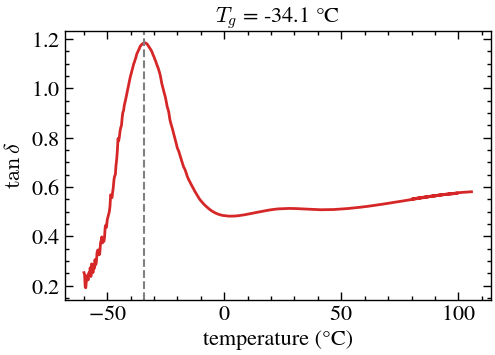

In [3]:
data = ramp.dataset
temperature = data.data_arrays[data.data_array_names.index("temperature")]
tan_delta = data.data_arrays[data.data_array_names.index("tan(delta)")]
tg_unit = ramp.details["tg_unit"]

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(temperature, tan_delta, color="tab:red", lw=2)
for t_peak in ramp.tan_delta_peaks.temperatures:
    ax.axvline(t_peak, color="0.5", ls="--", lw=1.5)
ax.set(xlabel=axis_label(data, "temperature"), ylabel=r"$\tan\delta$",
       title=f"$T_g$ = {ramp.tg:.1f} {tg_unit}")
plt.show()

Values interpolated at `use_temps` are in a second dataset, ready for tables or export with `ramp.to_excel(path)`.

In [4]:
extracted = ramp.extracted_dataset
for name, unit, values in zip(extracted.data_array_names, extracted.data_array_units, extracted.data_arrays):
    print(f"{name:>16} [{unit}]: " + ", ".join(f"{v:.3g}" for v in values))

     temperature [°C]: -50, -25, 0, 25, 60, 100
 storage modulus [Pa]: 8.55e+07, 3.27e+06, 8.49e+05, 4.08e+05, 1.98e+05, 1.05e+05
    loss modulus [Pa]: 3.98e+07, 3.13e+06, 4.11e+05, 2.09e+05, 1.03e+05, 6.04e+04
      tan(delta) []: 0.465, 0.958, 0.484, 0.513, 0.52, 0.577


## $T_g$ from the storage modulus

The onset $T_g$ is the intersection of two tangents to $\log G'(T)$:

- the **glassy tangent**, a straight line fitted to the glassy plateau over the first 12.5 % of the analysis range (`glassy_fraction`, the TRIOS default);
- the **inflection tangent**, through the point of steepest decrease of $G'$, the minimum of $\mathrm{d}\log G'/\mathrm{d}T$.

$\log G'$ is smoothed (Savitzky–Golay, `smoothing` = 5 degrees) before differentiation. The analysis range must start on the glassy plateau and contain the inflection; by default it runs from the first point to as far above the inflection as that point lies below it, and it can be set with `onset_range`. If the ramp starts inside the transition, a warning is issued and the onset is not reliable.

`tg_method="both"` reports both definitions; `ramp.tg` stays the $\tan\delta$ peak and `tg_method="storage_modulus"` makes the onset the reported $T_g$.

In [5]:
ramp_both = TemperatureRampAnalysis(steps_to_merge=["Temperature Ramp"], tg_method="both")(experiment)
print(ramp_both.summary())

Angular frequency: 6.28 rad/s
Frequency: 1 Hz
Tg (tan(delta) peak): -34.1 °C
Tg (storage modulus onset): -46.7 °C
Storage modulus inflection: -40.8 °C


`plot_onset()` shows the construction: top, $G'$ with the glassy fit range (shaded), the glassy tangent (dashed), the inflection tangent (dotted) and their intersection; bottom, $\mathrm{d}\log G'/\mathrm{d}T$, whose minimum is the inflection.

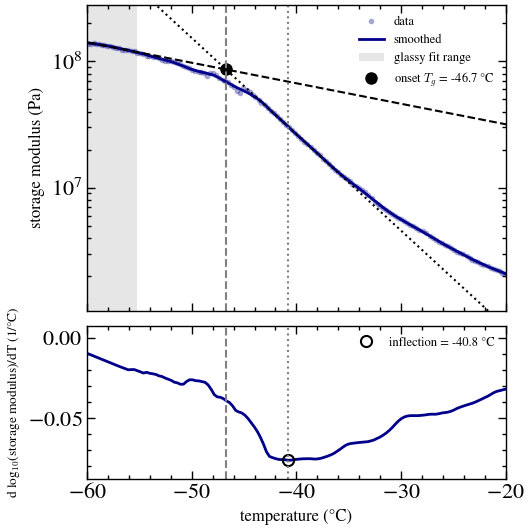

In [6]:
fig, axes = ramp_both.plot_onset(xlim=(-60, -20))
plt.show()

Both values on the full ramp: the inflection of $G'$ lies several degrees below the $\tan\delta$ peak.

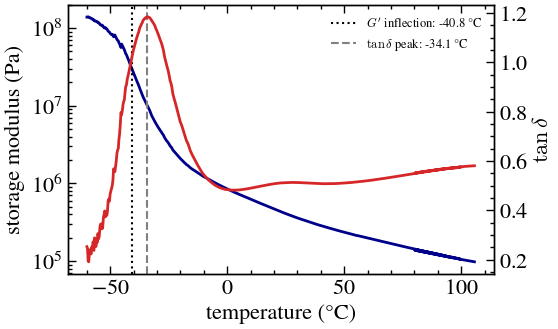

In [7]:
storage_modulus = data.data_arrays[data.data_array_names.index("storage modulus")]
values = ramp_both.tg_values

fig, ax_g = plt.subplots(figsize=(5.5, 3.5))
ax_t = ax_g.twinx()
ax_g.semilogy(temperature, storage_modulus, color="darkblue", lw=2)
ax_t.plot(temperature, tan_delta, color="tab:red", lw=2)
ax_g.axvline(values["Storage modulus inflection"], color="k", ls=":", lw=1.5,
             label=f"$G'$ inflection: {values['Storage modulus inflection']:.1f} {tg_unit}")
ax_g.axvline(values["Tg (tan(delta) peak)"], color="0.5", ls="--", lw=1.5,
             label=rf"$\tan\delta$ peak: {values['Tg (tan(delta) peak)']:.1f} {tg_unit}")
ax_g.set(xlabel=axis_label(data, "temperature"), ylabel=axis_label(data, "storage modulus"))
ax_t.set_ylabel(r"$\tan\delta$")
ax_g.legend(loc="upper right", fontsize=9)
plt.show()

## Several $\tan\delta$ peaks

Materials with two phases or a secondary relaxation can show more than one $\tan\delta$ peak. $\tan\delta$ is smoothed over `smoothing` degrees and its peaks are found with `scipy.signal.find_peaks`; the most prominent is $T_g$. A further peak is reported in `ramp.tan_delta_peaks` when

- its prominence is at least `tan_delta_prominence` (default 3 %) of the $\tan\delta$ range, and
- its width at half prominence is at most `tan_delta_max_width` (default 1.5) times that of the $T_g$ peak, so broad rises of $\tan\delta$ towards flow are not counted as transitions.

The ramps in this tutorial have a single transition.

## Several files

The same transform is applied to each file to compare $T_g$ across samples measured at the same frequency.

In [8]:
ramp_files = ["dhr3_trios_temp_ramp_1.txt", "dhr30_trios_temp_ramp_2.txt",
              "dhr3_trios_temp_ramp_3.txt", "dhr3_trios_temp_ramp_4.txt"]
for name in ramp_files:
    result = ramp_analysis(read_file(DATA / name, file_reader=TriosRheoReader,
                                     create_composite_datasets=True))
    d = result.details
    print(f"{name}: Tg = {result.tg:.1f} {d['tg_unit']} at {d['frequency']:.3g} {d['frequency_unit']}")

dhr3_trios_temp_ramp_1.txt: Tg = -11.9 °C at 1 Hz
dhr30_trios_temp_ramp_2.txt: Tg = -32.5 °C at 1 Hz
dhr3_trios_temp_ramp_3.txt: Tg = -34.1 °C at 1 Hz
dhr3_trios_temp_ramp_4.txt: Tg = -32.3 °C at 1 Hz


## References

- Whitcomb, K., "Measurement of Glass Transition Temperatures by Dynamic Mechanical Analysis and Rheology", TA Instruments application note RH100.